# Laboratorium 5 — wpływ korpusu na tokenizację BPE i embeddingi Word2Vec

Badany wyraz: **mysz** (zwierzę / urządzenie komputerowe). Wszystkie komórki wykonane od początku do końca.

In [1]:
import re, zlib, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
np.random.seed(0)

## 1. Korpus i próbka testowa

Trzy pule po 20 zdań: **A** – mysz = zwierzę, **B** – mysz = urządzenie, **C** – zdania bez słowa „mysz”. Zdania napisane samodzielnie na potrzeby ćwiczenia (źródło: własne). W A i B badana forma „mysz” występuje dokładnie raz w każdym zdaniu. Pula C zawiera też kilka zdań z wyrazami tematycznymi (bez „mysz”) oraz zdania neutralne.

**Przygotowanie tekstu:** zamiana na małe litery i wyciągnięcie ciągów znaków `\w+` (bez interpunkcji). Tokenizer BPE ma normalizer `Lowercase` + pretokenizer `Whitespace`, więc działa na tej samej normalizacji.

In [2]:
A = [
    'Kot złapał mysz i zaniósł ją do domu.',
    'Nora jest ciasna i ciemna, ale mysz czuje się w niej bezpiecznie.',
    'Mysz ma długi ogon, szare futro i małe czarne oczy.',
    'Kot cicho siedzi przy dziurze i czeka, aż mysz wyjdzie na zewnątrz.',
    'Ser leżał na stole, a mysz podkradała go w nocy.',
    'Szara mysz biega nocą po spiżarni i szuka jedzenia.',
    'Ogon pomaga, gdy mysz wspina się po cienkiej gałązce.',
    'Futro chroni mysz przed zimnem podczas jesieni.',
    'Kot patrzy na mysz, a jego ogon drży z podniecenia.',
    'Mysz gryzie ser i zostawia drobne okruszki na podłodze.',
    'Nora ma kilka wyjść, więc mysz łatwo ucieka przed drapieżnikiem.',
    'Mała mysz piszczy cicho, gdy kot podchodzi bliżej.',
    'Sowa poluje nocą, a mysz zamiera bez ruchu w trawie.',
    'Biała mysz laboratoryjna siedzi w klatce i je ziarno.',
    'Kot lubi ser, ale jeszcze bardziej lubi gonić mysz po kuchni.',
    'Młoda mysz ma miękkie futro i różowy ogon.',
    'Mysz domowa buduje gniazdo z trawy i skrawków papieru.',
    'Nora jest głęboka, a mysz trzyma w niej zapas ziarna.',
    'Kot uderzył łapą, lecz mysz uciekła do dziury w ścianie.',
    'Mysz ma wąsy, które pomagają jej wyczuwać przeszkody w ciemności.',
]

B = [
    'Komputer rozpoznał nową mysz zaraz po podłączeniu do portu USB.',
    'Ekran jest czarny, a kursor stoi w miejscu, bo mysz się zawiesiła.',
    'Klawiatura i mysz leżały obok monitora na białym biurku.',
    'Kabel był za krótki, więc mysz ledwo sięgała do krawędzi biurka.',
    'Bezprzewodowa mysz potrzebuje baterii i małego odbiornika USB.',
    'Gracz kupił nową mysz z dodatkowymi przyciskami do gier.',
    'Lewy przycisk, którym mysz klika, przestał działać po roku.',
    'Kółko przewija stronę, gdy mysz stoi spokojnie na podkładce.',
    'Ekran pokazał błąd, gdy mysz została nagle odłączona.',
    'Podkładka sprawia, że mysz sunie płynnie po blacie.',
    'Programista wymienił baterie, bo mysz przestała reagować na ruch ręki.',
    'Optyczny czujnik śledzi ruch, gdy mysz przesuwa się po biurku.',
    'Mysz bluetooth łączy się z laptopem bez dodatkowych przewodów.',
    'Klawiatura ma podświetlenie, a mysz świeci na niebiesko.',
    'Kursor zatrzymał się, bo mysz zawiesiła się na chwilę.',
    'Uczeń kliknął dwa razy, a mysz otworzyła folder na pulpicie.',
    'Komputer wyświetlił komunikat o sterowniku, gdy mysz została podłączona do laptopa.',
    'Kabel zaplątał się, kiedy mysz spadła z biurka.',
    'Ergonomiczna mysz zmniejsza zmęczenie nadgarstka przy długiej pracy.',
    'Ekran dotykowy działa bez urządzenia, ale mysz jest wygodniejsza w biurze.',
]

C = [
    'Komputer stoi na biurku, a obok leżą klawiatura i kabel.',
    'Ekran jest jasny, a kursor miga w polu tekstowym.',
    'Nowa klawiatura ma ciche przyciski i długi kabel.',
    'Komputer uruchamia się wolno, a ekran i kursor pojawiają się dopiero po chwili.',
    'Kot śpi na kanapie, a jego ogon zwisa na podłogę.',
    'Ser kupimy w sklepie, a chleb w piekarni.',
    'Nora lisa jest ukryta pod korzeniami starego dębu.',
    'Futro owcy jest gęste i ciepłe zimą.',
    'Rano rozmawiamy z kolegami o planach na weekend.',
    'Studenci pracują z dokumentami i książkami w bibliotece.',
    'Dzieci bawią się zabawkami na dywanie w salonie.',
    'Pociąg do Lublina odjeżdża o ósmej z drugiego peronu.',
    'Wczoraj padał deszcz, więc spacer został odwołany.',
    'Babcia piecze ciasto z jabłkami na niedzielny obiad.',
    'Lekcja matematyki zaczyna się o dziewiątej w sali numer pięć.',
    'Rowerzyści jadą ścieżką wzdłuż rzeki i robią zdjęcia.',
    'Zupa pomidorowa jest gorąca, więc czekamy chwilę przed jedzeniem.',
    'Latem jeździmy nad jezioro z namiotem i rowerami.',
    'Sąsiad naprawia samochód w garażu każdego sobotniego popołudnia.',
    'Na zakończenie roku uczniowie dostali dyplomy i małe upominki.',
]

In [3]:
norm = lambda s: re.findall(r'\w+', s.lower())
ALL = A + B + C
slowa_korpusu = {w for s in ALL for w in norm(s)}
print('Liczebność pul A/B/C:', len(A), len(B), len(C), '| razem:', len(ALL), '| unikalnych zdań:', len(set(ALL)))
print('Wystąpień "mysz" w A/B/C:', [sum(norm(s).count('mysz') for s in P) for P in (A,B,C)])
print('Zdań z "mysz" dokładnie raz w A/B:', [sum(norm(s).count('mysz')==1 for s in P) for P in (A,B)])
print('Różnych wyrazów w korpusie:', len(slowa_korpusu))

Liczebność pul A/B/C: 20 20 20 | razem: 60 | unikalnych zdań: 60
Wystąpień "mysz" w A/B/C: [20, 20, 0]
Zdań z "mysz" dokładnie raz w A/B: [20, 20]
Różnych wyrazów w korpusie: 331


In [4]:
PARY = [('mysz','myszami'), ('kot','kotami'), ('komputer','komputerami'), ('kabel','kablami'),
        ('klawiatura','klawiaturami'), ('nora','norami'), ('ser','serami')]
for w, n in PARY:
    print(f'{w:12s} w korpusie: {w in slowa_korpusu!s:5s} | {n:14s} w korpusie: {n in slowa_korpusu}')
widziane   = [w for w,_ in PARY]
niewidziane = [n for _,n in PARY]
assert all(w in slowa_korpusu for w in widziane) and not any(n in slowa_korpusu for n in niewidziane)

mysz         w korpusie: True  | myszami        w korpusie: False
kot          w korpusie: True  | kotami         w korpusie: False
komputer     w korpusie: True  | komputerami    w korpusie: False
kabel        w korpusie: True  | kablami        w korpusie: False
klawiatura   w korpusie: True  | klawiaturami   w korpusie: False
nora         w korpusie: True  | norami         w korpusie: False
ser          w korpusie: True  | serami         w korpusie: False


## 2. BPE

**Hipoteza.** Zwiększanie `vocab_size` zmniejszy średnią liczbę tokenów dla obu grup form. Formy widziane w treningu dojdą do ok. 1 token na słowo (całe słowo staje się tokenem), a niewidziane zatrzymają się powyżej 1, bo ich całej formy nie ma w treningu — zostanie temat + końcówka (lub kilka fragmentów). Tokenu `[UNK]` nie spodziewam się, bo wszystkie litery tych form występują w korpusie.

In [5]:
def trenuj_bpe(limit):
    t = Tokenizer(models.BPE(unk_token='[UNK]'))
    t.normalizer = normalizers.Lowercase()
    t.pre_tokenizer = pre_tokenizers.Whitespace()
    t.train_from_iterator(ALL, trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1))
    return t

LIMITY = [100, 300, 700]
TOK = {l: trenuj_bpe(l) for l in LIMITY}

wiersze = []
for l, t in TOK.items():
    r = {'limit vocab_size': l, 'faktyczny rozmiar': t.get_vocab_size()}
    for nazwa, grupa in (('widziane', widziane), ('niewidziane', niewidziane)):
        enc = [t.encode(w).tokens for w in grupa]
        r[f'śr. tokenów ({nazwa})'] = round(np.mean([len(e) for e in enc]), 2)
        r[f'formy z [UNK] ({nazwa})'] = sum('[UNK]' in e for e in enc)
    wiersze.append(r)
pd.DataFrame(wiersze)

,limit vocab_size,faktyczny rozmiar,śr. tokenów (widziane),formy z [UNK] (widziane),śr. tokenów (niewidziane),formy z [UNK] (niewidziane)
0,100,100,2.86,0,4.43,0
1,300,300,1.00,0,3.00,0
2,700,700,1.00,0,2.71,0


In [6]:
for w, n in PARY:
    print(f'{w:12s}', ' | '.join(f'{l}: {TOK[l].encode(w).tokens}' for l in LIMITY))
print()
for w, n in PARY:
    print(f'{n:14s}', ' | '.join(f'{l}: {TOK[l].encode(n).tokens}' for l in LIMITY))

mysz         100: ['mysz'] | 300: ['mysz'] | 700: ['mysz']
kot          100: ['kot'] | 300: ['kot'] | 700: ['kot']
komputer     100: ['ko', 'm', 'p', 'ut', 'er'] | 300: ['komputer'] | 700: ['komputer']
kabel        100: ['ka', 'be', 'l'] | 300: ['kabel'] | 700: ['kabel']
klawiatura   100: ['k', 'la', 'wia', 't', 'u', 'ra'] | 300: ['klawiatura'] | 700: ['klawiatura']
nora         100: ['no', 'ra'] | 300: ['nora'] | 700: ['nora']
ser          100: ['s', 'er'] | 300: ['ser'] | 700: ['ser']

myszami        100: ['mysz', 'a', 'mi'] | 300: ['mysz', 'a', 'mi'] | 700: ['mysz', 'a', 'mi']
kotami         100: ['kot', 'a', 'mi'] | 300: ['kot', 'a', 'mi'] | 700: ['kot', 'a', 'mi']
komputerami    100: ['ko', 'm', 'p', 'ut', 'e', 'ra', 'mi'] | 300: ['komput', 'e', 'ra', 'mi'] | 700: ['komput', 'e', 'rami']
kablami        100: ['ka', 'b', 'la', 'mi'] | 300: ['ka', 'bla', 'mi'] | 700: ['ka', 'bla', 'mi']
klawiaturami   100: ['k', 'la', 'wia', 't', 'u', 'ra', 'mi'] | 300: ['klawiatura', 'mi'] | 700: ['

In [7]:
# dwie niewidziane formy do analizy + w jakich formach treningowych występują ich fragmenty
def formy_z_fragmentem(frag, limit=8):
    return sorted(w for w in slowa_korpusu if frag in w)[:limit]

for n in ['komputerami', 'klawiaturami']:
    print('=====', n)
    for l in LIMITY:
        toks = TOK[l].encode(n).tokens
        print(f'  limit {l} (rozmiar {TOK[l].get_vocab_size()}):', toks)
    wszystkie = {tk for l in LIMITY for tk in TOK[l].encode(n).tokens if len(tk) > 1}
    for tk in sorted(wszystkie):
        print(f'  fragment {tk!r} w formach treningowych:', formy_z_fragmentem(tk))

===== komputerami
  limit 100 (rozmiar 100): ['ko', 'm', 'p', 'ut', 'e', 'ra', 'mi']
  limit 300 (rozmiar 300): ['komput', 'e', 'ra', 'mi']
  limit 700 (rozmiar 700): ['komput', 'e', 'rami']
  fragment 'ko' w formach treningowych: ['dodatkowych', 'dodatkowymi', 'dotykowy', 'kolegami', 'komputer', 'komunikat', 'korzeniami', 'kot']
  fragment 'komput' w formach treningowych: ['komputer']
  fragment 'mi' w formach treningowych: ['dodatkowymi', 'dokumentami', 'ergonomiczna', 'jabłkami', 'kolegami', 'korzeniami', 'książkami', 'miejscu']
  fragment 'ra' w formach treningowych: ['drapieżnikiem', 'ekran', 'garażu', 'gracz', 'klawiatura', 'krawędzi', 'laboratoryjna', 'monitora']
  fragment 'rami' w formach treningowych: ['programista', 'rowerami']
  fragment 'ut' w formach treningowych: ['futro', 'komputer']
===== klawiaturami
  limit 100 (rozmiar 100): ['k', 'la', 'wia', 't', 'u', 'ra', 'mi']
  limit 300 (rozmiar 300): ['klawiatura', 'mi']
  limit 700 (rozmiar 700): ['klawiatura', 'mi']
  frag

## 3. Word2Vec — dwa warianty korpusu

Ta sama pula C w obu wariantach. Wariant 1: 12 zdań A + 4 zdania B. Wariant 2: 4 zdania A + 12 zdań B. W obu: 36 zdań i 16 wystąpień „mysz”.

Ustawienia: `vector_size=50, window=3, min_count=2, sg=1, epochs=100, seed=0, workers=1`. Dodatkowo własny `hashfxn` (crc32), żeby wynik był powtarzalny między uruchomieniami. Epoki: przy 200 (domyślnie w notatniku) na tak małym korpusie wszystkie cosinusy wychodziły ≈ 0,98 i ranking był nieczytelny, dlatego 100.

In [8]:
W1 = C + A[:12] + B[:4]
W2 = C + A[:4] + B[:12]
licz = lambda S: sum(norm(s).count('mysz') for s in S)
print('Zdań:', len(W1), len(W2), '| wystąpień "mysz":', licz(W1), licz(W2))

stab = lambda s: zlib.crc32(s.encode('utf-8'))
def trenuj_w2v(S, seed=0):
    return Word2Vec([norm(s) for s in S], vector_size=50, window=3, min_count=2, sg=1,
                    epochs=100, seed=seed, workers=1, hashfxn=stab)
m1, m2 = trenuj_w2v(W1), trenuj_w2v(W2)
print('Rozmiar słownika modeli:', len(m1.wv), len(m2.wv))
n1 = m1.wv.most_similar('mysz', topn=5); n2 = m2.wv.most_similar('mysz', topn=5)
pd.DataFrame({'#': range(1,6),
              'wariant 1 (12 zwierzę / 4 urządzenie)': [f'{w} ({c:.2f})' for w,c in n1],
              'wariant 2 (4 zwierzę / 12 urządzenie)': [f'{w} ({c:.2f})' for w,c in n2]}).set_index('#')

Zdań: 36 36 | wystąpień "mysz": 16 16
Rozmiar słownika modeli: 32 33


,wariant 1 (12 zwierzę / 4 urządzenie),wariant 2 (4 zwierzę / 12 urządzenie)
#,,
1,kursor (0.65),kabel (0.62)
2,a (0.63),po (0.58)
3,nora (0.63),obok (0.56)
4,i (0.58),i (0.53)
5,ekran (0.57),komputer (0.52)


In [9]:
wypadly = [w for w,_ in n1 if w not in dict(n2)]
for w in wypadly:
    print(f'{w!r}: w modelu 2: {w in m2.wv} | liczność w W1: {m1.wv.get_vecattr(w,"count")}',
          f'| w W2: {m2.wv.get_vecattr(w,"count") if w in m2.wv else "brak"}', end='')
    print(f' | cos(mysz, {w}) w m2 = {m2.wv.similarity("mysz", w):.2f}' if w in m2.wv else '')
print('Słowa tylko w modelu 1:', sorted(set(m1.wv.index_to_key) - set(m2.wv.index_to_key)))
print('Słowa tylko w modelu 2:', sorted(set(m2.wv.index_to_key) - set(m1.wv.index_to_key)))

'kursor': w modelu 2: True | liczność w W1: 3 | w W2: 3 | cos(mysz, kursor) w m2 = 0.36
'a': w modelu 2: True | liczność w W1: 8 | w W2: 6 | cos(mysz, a) w m2 = 0.46
'nora': w modelu 2: True | liczność w W1: 3 | w W2: 2 | cos(mysz, nora) w m2 = 0.10
'ekran': w modelu 2: True | liczność w W1: 3 | w W2: 4 | cos(mysz, ekran) w m2 = 0.46
Słowa tylko w modelu 1: ['cicho', 'jego', 'przed', 'ser']
Słowa tylko w modelu 2: ['bo', 'nową', 'roku', 'ruch', 'usb']


In [10]:
def pokaz(slowo, S, tylko_mysz=True):
    for s in S:
        if slowo in norm(s) and (not tylko_mysz or 'mysz' in norm(s)):
            print('  -', s)
for w in ['kursor', 'nora', 'kabel', 'komputer']:
    print(f'[{w}] zdania z "mysz" w W1:'); pokaz(w, W1)
    print(f'[{w}] zdania z "mysz" w W2:'); pokaz(w, W2)

[kursor] zdania z "mysz" w W1:
  - Ekran jest czarny, a kursor stoi w miejscu, bo mysz się zawiesiła.
[kursor] zdania z "mysz" w W2:
  - Ekran jest czarny, a kursor stoi w miejscu, bo mysz się zawiesiła.
[nora] zdania z "mysz" w W1:
  - Nora jest ciasna i ciemna, ale mysz czuje się w niej bezpiecznie.
  - Nora ma kilka wyjść, więc mysz łatwo ucieka przed drapieżnikiem.
[nora] zdania z "mysz" w W2:
  - Nora jest ciasna i ciemna, ale mysz czuje się w niej bezpiecznie.
[kabel] zdania z "mysz" w W1:
  - Kabel był za krótki, więc mysz ledwo sięgała do krawędzi biurka.
[kabel] zdania z "mysz" w W2:
  - Kabel był za krótki, więc mysz ledwo sięgała do krawędzi biurka.
[komputer] zdania z "mysz" w W1:
  - Komputer rozpoznał nową mysz zaraz po podłączeniu do portu USB.
[komputer] zdania z "mysz" w W2:
  - Komputer rozpoznał nową mysz zaraz po podłączeniu do portu USB.


**Stabilność względem ziarna** (te same ustawienia, seed 0–4). Sprawdzam, czy różnice między wariantami nie są tylko szumem losowania.

In [11]:
for sd in range(5):
    a, b = trenuj_w2v(W1, sd), trenuj_w2v(W2, sd)
    print('seed', sd)
    print('  W1:', [w for w,_ in a.wv.most_similar('mysz', topn=5)])
    print('  W2:', [w for w,_ in b.wv.most_similar('mysz', topn=5)])

seed 0
  W1: ['kursor', 'a', 'nora', 'i', 'ekran']
  W2: ['kabel', 'po', 'obok', 'i', 'komputer']
seed 1
  W1: ['na', 'ogon', 'i', 'komputer', 'a']
  W2: ['a', 'biurku', 'i', 'na', 'obok']
seed 2
  W1: ['klawiatura', 'i', 'kursor', 'komputer', 'kot']
  W2: ['ekran', 'kursor', 'stoi', 'bo', 'i']
seed 3
  W1: ['i', 'ma', 'kabel', 'na', 'się']
  W2: ['i', 'a', 'klawiatura', 'kabel', 'biurku']
seed 4
  W1: ['a', 'się', 'i', 'kursor', 'obok']
  W2: ['i', 'a', 'ogon', 'się', 'jest']


## 4. Grupy tematyczne i PCA

Grupy wybrane **przed** obejrzeniem wyników:

**zwierzę:** kot, ser, nora, ogon, futro — kot poluje na mysz, ser jest jej przysmakiem, nora to jej dom, ogon i futro to cechy ciała.

**urządzenie:** komputer, klawiatura, kursor, ekran, kabel — elementy zestawu komputerowego, z którymi mysz współpracuje.

Okno `min_count=2`: w wariancie 1 każde z tych słów ma co najmniej 3 wystąpienia (sprawdzenie poniżej).

In [12]:
GA = ['kot', 'ser', 'nora', 'ogon', 'futro']
GB = ['komputer', 'klawiatura', 'kursor', 'ekran', 'kabel']
print({w: int(m1.wv.get_vecattr(w, 'count')) for w in GA + GB})

{'kot': 5, 'ser': 3, 'nora': 3, 'ogon': 4, 'futro': 3, 'komputer': 3, 'klawiatura': 3, 'kursor': 3, 'ekran': 3, 'kabel': 3}


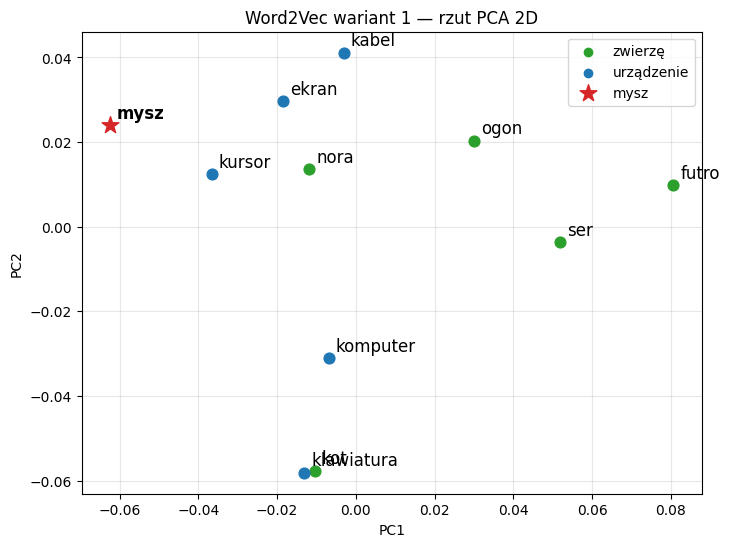

Wariancja wyjaśniona przez PC1, PC2: [0.226 0.163]


In [13]:
slowa = GA + GB + ['mysz']
X = np.stack([m1.wv[w] for w in slowa])
XY = PCA(n_components=2, random_state=0).fit_transform(X)
kolor = ['tab:green']*len(GA) + ['tab:blue']*len(GB) + ['tab:red']
plt.figure(figsize=(8,6))
for (x,y), w, c in zip(XY, slowa, kolor):
    plt.scatter(x, y, c=c, s=160 if w=='mysz' else 60, marker='*' if w=='mysz' else 'o', zorder=3)
    plt.annotate(w, (x,y), fontsize=12, fontweight='bold' if w=='mysz' else 'normal', xytext=(5,5), textcoords='offset points')
plt.scatter([], [], c='tab:green', label='zwierzę'); plt.scatter([], [], c='tab:blue', label='urządzenie')
plt.scatter([], [], c='tab:red', marker='*', s=160, label='mysz')
plt.legend(); plt.grid(alpha=0.3); plt.title('Word2Vec wariant 1 — rzut PCA 2D')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.savefig('pca_lab5.png', dpi=150, bbox_inches='tight'); plt.show()
print('Wariancja wyjaśniona przez PC1, PC2:', PCA(n_components=2, random_state=0).fit(X).explained_variance_ratio_.round(3))

In [14]:
def sr(pary): return float(np.mean([m1.wv.similarity(a, b) for a, b in pary]))
wewn_A = list(itertools.combinations(GA, 2)); wewn_B = list(itertools.combinations(GB, 2)); miedzy = list(itertools.product(GA, GB))
print(f'wewnątrz zwierzę    ({len(wewn_A)} par): {sr(wewn_A):.3f}')
print(f'wewnątrz urządzenie ({len(wewn_B)} par): {sr(wewn_B):.3f}')
print(f'między grupami      ({len(miedzy)} par): {sr(miedzy):.3f}')
for p in [('klawiatura','kursor'), ('komputer','ekran'), ('kot','ogon'), ('ser','futro'), ('kot','kabel')]:
    print(p, round(float(m1.wv.similarity(*p)), 3))

wewnątrz zwierzę    (10 par): 0.178
wewnątrz urządzenie (10 par): 0.436
między grupami      (25 par): 0.282
('klawiatura', 'kursor') 0.407
('komputer', 'ekran') 0.48
('kot', 'ogon') 0.201
('ser', 'futro') 0.051
('kot', 'kabel') 0.302
